In [1]:
# Ensure we can import from our 'src' package
import sys
import os

project_root = os.path.abspath(os.path.join(os.getcwd(), '..'))
if project_root not in sys.path:
    sys.path.insert(0, project_root)

# Now import our simulated device and detector
from src.simulated_display import SimulatedLEDDisplay # Still good to have this if you want to use the base class
from src.simulated_detector import SimulatedParticleDetector # Our new detector!

import matplotlib.pyplot as plt
import numpy as np

# Set up matplotlib for inline display
%matplotlib inline
plt.rcParams['figure.figsize'] = (6, 6) # Adjust figure size for better visualization

In [2]:
detector_width = 32 # Let's make it a bit larger for events
detector_height = 32

# Initialize with a dark background to simulate a 'cold' detector
my_detector = SimulatedParticleDetector(detector_width, detector_height, initial_background=(10, 10, 10))

print(f"Detector Firmware Version: {my_detector.get_firmware_version()}")
print(f"Max energy per pixel: {my_detector.max_energy_per_pixel}")

SimulatedLEDDisplay initialized: 32x32 pixels.
Hardware boot sequence complete.
SimulatedParticleDetector initialized: 32x32 cells.
Detector Firmware Version: v1.0.0-alpha
Max energy per pixel: 255


Display filled with color: (0, 0, 0)
Display cleared.
Simulating particle hit at (16.0,16.0) with energy 500.00, radius 5.0
Retrieving display data...
Total deposited energy read: 3810


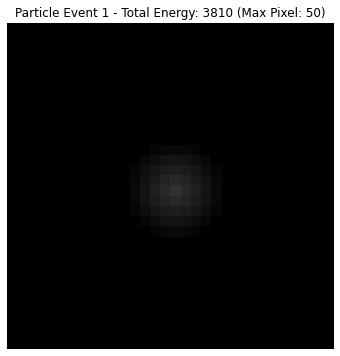

In [3]:
my_detector.clear_display() # Start with a clean slate

# Simulate a particle hitting near the center with some energy and spread
my_detector.simulate_particle_hit(
    impact_x=detector_width / 2,
    impact_y=detector_height / 2,
    energy_deposited=500, # This total energy will be distributed
    spread_radius=5.0
)

# Get and visualize the event
event_data = my_detector.get_display_data()
total_energy = my_detector.get_total_deposited_energy()
max_pixel_val = my_detector.get_max_pixel_value()

plt.imshow(event_data)
plt.title(f"Particle Event 1 - Total Energy: {total_energy:.0f} (Max Pixel: {max_pixel_val})")
plt.axis('off')
plt.show()

Display filled with color: (0, 0, 0)
Display cleared.
Simulating particle hit at (10.0,10.0) with energy 300.00, radius 3.0
Simulating particle hit at (25.0,5.0) with energy 800.00, radius 7.0
Simulating particle hit at (8.0,28.0) with energy 600.00, radius 4.0
Adding background noise with max level: 15
Retrieving display data...
Total deposited energy read: 38783


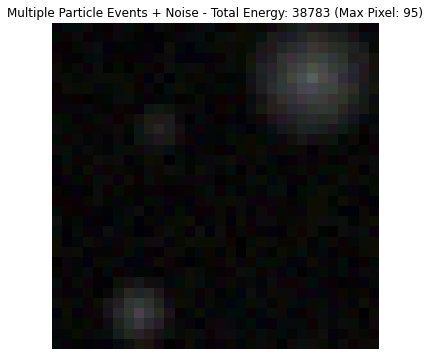

Performing hardware reset...
Hardware reset complete.


In [4]:
my_detector.clear_display() # Clear for a new event

# Simulate a few more hits in different locations with varying energies
my_detector.simulate_particle_hit(10, 10, 300, 3.0) # Smaller, lower energy hit
my_detector.simulate_particle_hit(25, 5, 800, 7.0) # Larger, higher energy hit
my_detector.simulate_particle_hit(8, 28, 600, 4.0) # Medium hit

# Add some background noise
my_detector.add_background_noise(noise_level=15, seed=42)

event_data = my_detector.get_display_data()
total_energy = my_detector.get_total_deposited_energy()
max_pixel_val = my_detector.get_max_pixel_value()

plt.imshow(event_data)
plt.title(f"Multiple Particle Events + Noise - Total Energy: {total_energy:.0f} (Max Pixel: {max_pixel_val})")
plt.axis('off')
plt.show()

# Simulate a hardware reset at the end of an acquisition period
my_detector.reset_hardware()